# Analisis exploratorio de Netflix

Este notebook ejecuta el mismo flujo que `main.py` de forma interactiva.

In [2]:
from pathlib import Path
import sys
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.estilo import aplicar_estilo_minimalista
from src.evolucion_temporal import calcular_proporciones, construir_tabla_evolucion, graficar_evolucion
from src.joyas_ocultas import CATALOGO_GLOBAL, encontrar_joyas_ocultas, graficar_joyas
from src.motor_recomendacion import CATALOGO_SINOPSIS, construir_matriz_similitud, recomendar
from src.perfil_preferencias import calcular_top_generos, enriquecer_con_generos, graficar_preferencias
from src.tiempo_consumido import calcular_tiempo_consumido, cargar_actividad, formatear_tiempo, graficar_duraciones

aplicar_estilo_minimalista()
OUTPUT = ROOT / 'outputs' / 'graficos'
OUTPUT.mkdir(parents=True, exist_ok=True)
actividad = cargar_actividad(ROOT / 'data' / 'sample_viewing_activity.csv')

In [5]:
print(formatear_tiempo(calcular_tiempo_consumido(actividad)))
perfil = enriquecer_con_generos(actividad)
display(calcular_top_generos(perfil).to_frame('reproducciones'))
conteos = construir_tabla_evolucion(perfil)
proporciones = calcular_proporciones(conteos)
display(proporciones)

0 dias, 10 horas y 15 minutos


,reproducciones
Genre,
Ciencia Ficcion,6
Comedia,2
Accion,1
Animacion,1


Genre,Accion,Animacion,Ciencia Ficcion,Comedia
Periodo,,,,
2021,33.333333,0.0,66.666667,0.000000
2022,0.000000,0.0,33.333333,66.666667
2023,0.000000,25.0,75.000000,0.000000


Graficos de las preguntas 1, 2 y 3


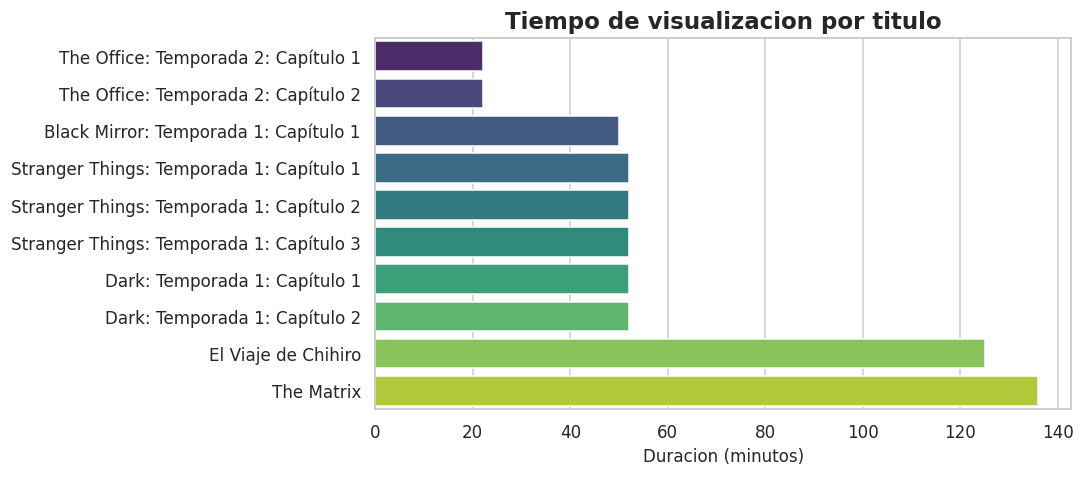

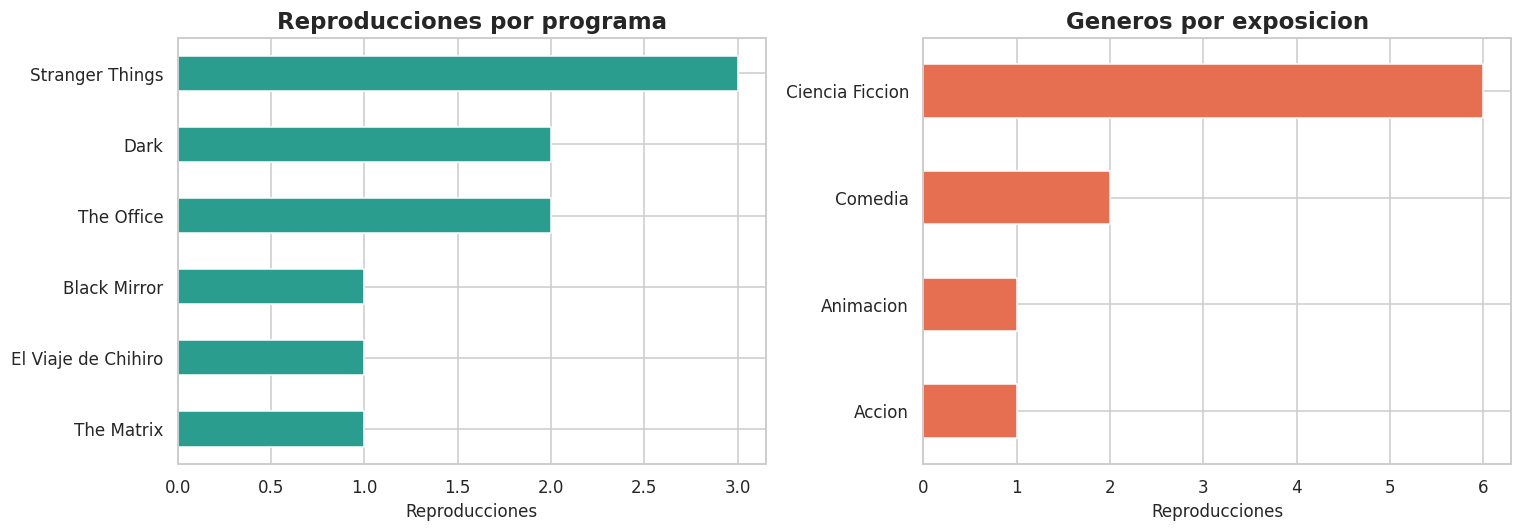

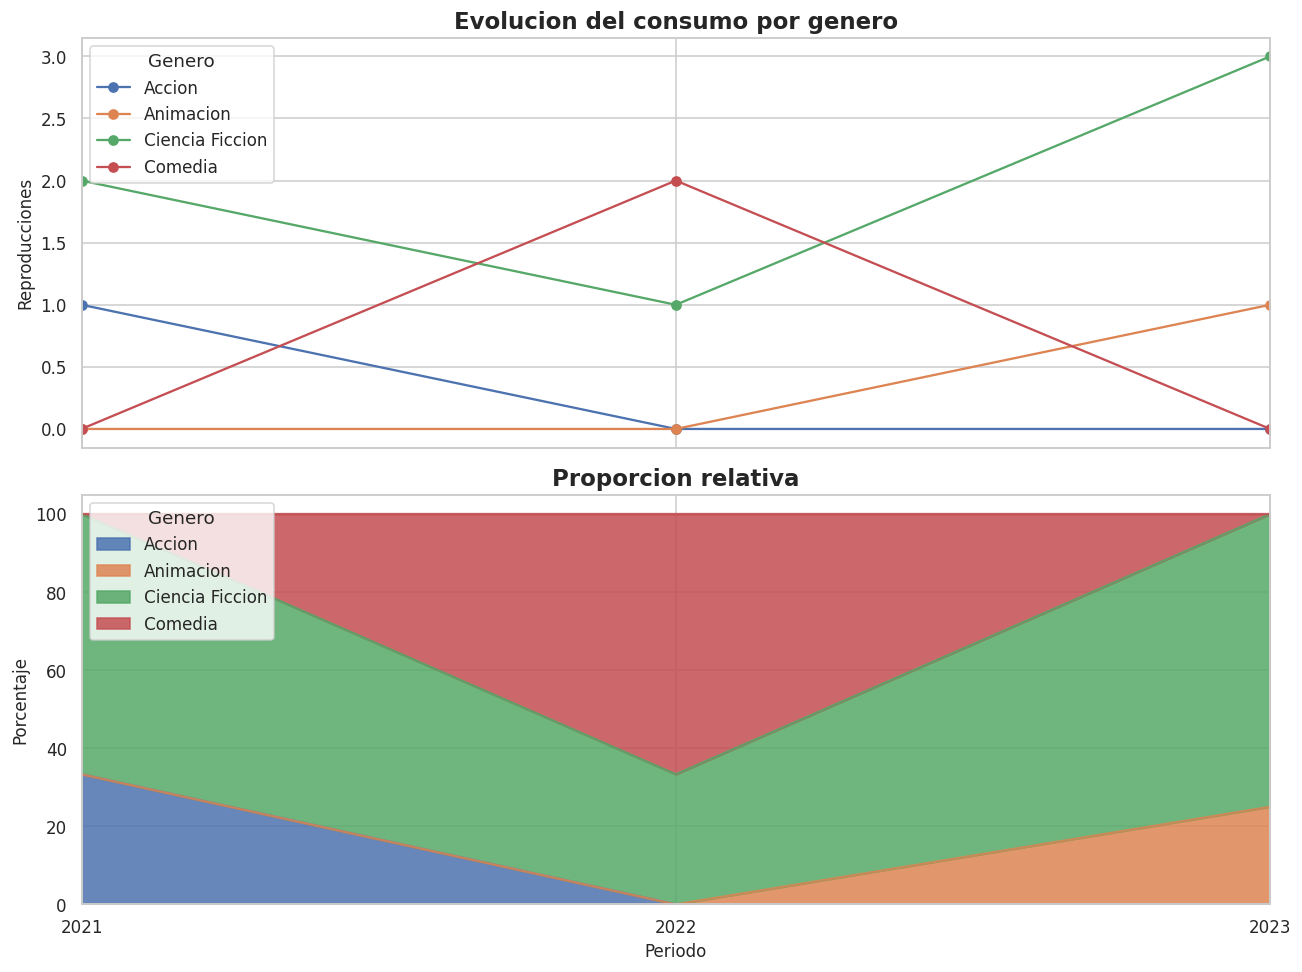

In [6]:
from IPython.display import Image, display

print('Graficos de las preguntas 1, 2 y 3')
graficar_duraciones(actividad, OUTPUT / '01_tiempo_consumido.png')
graficar_preferencias(perfil, OUTPUT / '02_perfil_preferencias.png')
graficar_evolucion(conteos, proporciones, OUTPUT / '03_evolucion_temporal.png')

display(Image(filename=str(OUTPUT / '01_tiempo_consumido.png')))
display(Image(filename=str(OUTPUT / '02_perfil_preferencias.png')))
display(Image(filename=str(OUTPUT / '03_evolucion_temporal.png')))

,Title,Genre,Popularity_Score
0,Primer,Ciencia Ficcion,15
1,Coherence,Ciencia Ficcion,20
2,Devs,Ciencia Ficcion,30
3,Fringe,Ciencia Ficcion,50
4,The OA,Ciencia Ficcion,60


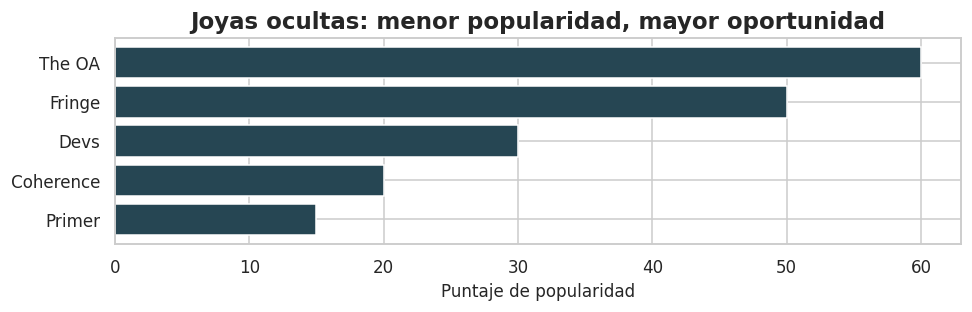

Recomendaciones para The Office:


[('Parks and Recreation', 0.6155090268252051),
 ('Space Force', 0.11427634287360969)]

Recomendaciones para Stranger Things:


[('Dark', 0.245543827245879)]

In [7]:
from IPython.display import Image, display

titulos_vistos = perfil['Programa'].unique().tolist()
genero = calcular_top_generos(perfil).index[0]
joyas = encontrar_joyas_ocultas(CATALOGO_GLOBAL, genero, titulos_vistos)
display(joyas)
graficar_joyas(joyas, OUTPUT / '04_joyas_ocultas.png')
display(Image(filename=str(OUTPUT / '04_joyas_ocultas.png')))

matriz, _ = construir_matriz_similitud(CATALOGO_SINOPSIS)
for titulo in ('The Office', 'Stranger Things'):
    print(f'Recomendaciones para {titulo}:')
    display(recomendar(titulo, CATALOGO_SINOPSIS, matriz))